<a href="https://colab.research.google.com/github/68070192/sign-language-digits-cnn/blob/main/notebooks/experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import shutil
import numpy as np
from PIL import Image
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import kagglehub

# 1. ล็อก Seed เพื่อให้ผลลัพธ์รันซ้ำได้ 100% (Reproducibility)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Working on device: {device}")

# 2. ดาวน์โหลด Dataset ต้นฉบับของ Arda Mavi (โหลดได้แน่นอน ไม่ติด 403)
print("Downloading Arda Mavi dataset...")
download_path = kagglehub.dataset_download("ardamavi/sign-language-digits-dataset")

# โหลดข้อมูล X, Y จากไฟล์ .npy
X = np.load(os.path.join(download_path, "X.npy"))
Y = np.load(os.path.join(download_path, "Y.npy"))
labels = np.argmax(Y, axis=1)

# 3. แตกไฟล์ Array ออกมาเป็นโฟลเดอร์รูปภาพ 0-9 อัตโนมัติ
data_dir = "sign_dataset_images"
if not os.path.exists(data_dir):
    print("Extracting images into folders 0-9...")
    for i in range(10):
        os.makedirs(os.path.join(data_dir, str(i)), exist_ok=True)

    for idx, (img_arr, label) in enumerate(zip(X, labels)):
        # แปลงเป็นภาพ RGB และเซฟลงโฟลเดอร์คลาส
        img_uint8 = (img_arr * 255).astype(np.uint8)
        img = Image.fromarray(img_uint8).convert("RGB")
        img.save(os.path.join(data_dir, str(label), f"{idx}.jpg"))
    print("Extraction complete!")
else:
    print("Image folders already exist.")

# 4. กำหนดค่าคงที่
IMG_SIZE = 64
BATCH_SIZE = 32

# 5. กำหนด Transforms (Train มี Augmentation / Val และ Test ไม่มี)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# 6. โหลด Dataset ด้วย ImageFolder และแบ่ง Train (70%) / Val (15%) / Test (15%)
full_dataset_train = datasets.ImageFolder(data_dir, transform=train_transform)
full_dataset_eval = datasets.ImageFolder(data_dir, transform=eval_transform)

num_samples = len(full_dataset_train)
indices = list(range(num_samples))

np.random.seed(42)
np.random.shuffle(indices)

train_end = int(0.70 * num_samples)
val_end = int(0.85 * num_samples)

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

train_set = Subset(full_dataset_train, train_idx)
val_set = Subset(full_dataset_eval, val_idx)
test_set = Subset(full_dataset_eval, test_idx)

# 7. สร้าง DataLoader
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"\n--- Data Split Summary ---")
print(f"Total Samples : {num_samples}")
print(f"Train Set     : {len(train_set)} samples ({len(train_loader)} batches)")
print(f"Validation Set: {len(val_set)} samples ({len(val_loader)} batches)")
print(f"Test Set      : {len(test_set)} samples ({len(test_loader)} batches)")
print(f"Class Mapping : {full_dataset_train.class_to_idx}")

Working on device: cuda


100%|██████████| 16.8M/16.8M [00:00<00:00, 85.7MB/s]

Extracting files...


Extracting images into folders 0-9...
Extraction complete!

--- Data Split Summary ---
Total Samples : 2062
Train Set     : 1443 samples (46 batches)
Validation Set: 309 samples (10 batches)
Test Set      : 310 samples (10 batches)
Class Mapping : {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9}


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

# กำหนดค่าตัวแปรขนาดภาพและอุปกรณ์ประมวลผลให้เซลล์นี้โดยตรง
IMG_SIZE = 64
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. นิยามโครงสร้าง Baseline Model (Linear Layer ชั้นเดียวบนพิกเซลภาพ)
class BaselineLinear(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * IMG_SIZE * IMG_SIZE, num_classes)
        )

    def forward(self, x):
        return self.net(x)

# 2. ฟังก์ชัน Training Loop กลาง (เก็บ Log และเซฟน้ำหนักโมเดลรอบที่ Val Loss ดีที่สุด)
def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3, weight_decay=1e-4, save_path="best_model.pth"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")

    for epoch in range(epochs):
        # --- โหมด Training ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # --- โหมด Validation ---
        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # บันทึกโมเดลเฉพาะรอบที่ Validation Loss ต่ำที่สุด
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:02d}/{epochs}] | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")

    return history

# 3. สั่งรันเทรน Baseline (ใช้เวลาประมาณ 10-15 วินาที)
print("=== Starting Baseline Training ===")
baseline_model = BaselineLinear(num_classes=10)
hist_baseline = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    lr=1e-3,
    save_path="best_baseline.pth"
)

# 4. ฟังก์ชันประเมินผลบน Test Set
def evaluate_on_test(model, weight_path, loader):
    model.load_state_dict(torch.load(weight_path, map_location=device))
    model.to(device)
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")
    return acc, f1

base_acc, base_f1 = evaluate_on_test(BaselineLinear(10), "best_baseline.pth", test_loader)
print(f"\n[Baseline Test Result] Accuracy: {base_acc*100:.2f}% | Macro-F1: {base_f1:.4f}")

=== Starting Baseline Training ===
Epoch [01/15] | Train Loss: 2.3597, Acc: 0.3375 | Val Loss: 1.5077, Acc: 0.4951
Epoch [05/15] | Train Loss: 1.1124, Acc: 0.6826 | Val Loss: 0.9053, Acc: 0.7087
Epoch [10/15] | Train Loss: 0.9134, Acc: 0.7193 | Val Loss: 1.0594, Acc: 0.7346
Epoch [15/15] | Train Loss: 1.1700, Acc: 0.6999 | Val Loss: 1.3615, Acc: 0.6343

[Baseline Test Result] Accuracy: 70.00% | Macro-F1: 0.7046


In [3]:
import torch
import torch.nn as nn

# 1. นิยามสถาปัตยกรรม Custom CNN
class SignLanguageCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Feature Extraction: สกัดขอบภาพและรูปทรงของนิ้วมือ
        self.features = nn.Sequential(
            # Block 1: [B, 3, 64, 64] -> [B, 32, 32, 32]
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2: [B, 32, 32, 32] -> [B, 64, 16, 16]
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3: [B, 64, 16, 16] -> [B, 128, 8, 8]
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Classification Head: ลดขนาด Feature map และจำแนก 10 คลาส
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), # ยุบมิติให้เหลือ [B, 128, 1, 1]
            nn.Flatten(),                 # [B, 128]
            nn.Dropout(p=0.4),            # Regularization สุ่มปิด Node 40%
            nn.Linear(128, num_classes)   # ทำนายผล 10 คลาส
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# 2. เริ่มต้นเทรนโมเดล Custom CNN (25 Epochs)
print("=== Starting Custom CNN Training ===")
cnn_model = SignLanguageCNN(num_classes=10)

hist_cnn = train_model(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=25,
    lr=1e-3,
    weight_decay=1e-4,
    save_path="best_cnn.pth"
)

# 3. ประเมินผลบน Test Set
cnn_acc, cnn_f1 = evaluate_on_test(SignLanguageCNN(10), "best_cnn.pth", test_loader)

# 4. สรุปเปรียบเทียบผลลัพธ์ระหว่าง Baseline กับ Custom CNN
print("\n" + "="*45)
print("             TEST EVALUATION SUMMARY")
print("="*45)
print(f"Baseline (Linear) : Accuracy = {base_acc*100:6.2f}% | Macro-F1 = {base_f1:.4f}")
print(f"Custom CNN        : Accuracy = {cnn_acc*100:6.2f}% | Macro-F1 = {cnn_f1:.4f}")
print(f"Improvement       : +{(cnn_acc - base_acc)*100:5.2f}% Accuracy")
print("="*45)

=== Starting Custom CNN Training ===
Epoch [01/25] | Train Loss: 2.2817, Acc: 0.1601 | Val Loss: 2.1949, Acc: 0.1618
Epoch [05/25] | Train Loss: 1.7210, Acc: 0.4345 | Val Loss: 1.6186, Acc: 0.4595
Epoch [10/25] | Train Loss: 1.3912, Acc: 0.5336 | Val Loss: 1.2245, Acc: 0.6990
Epoch [15/25] | Train Loss: 1.0853, Acc: 0.6632 | Val Loss: 1.4122, Acc: 0.4531
Epoch [20/25] | Train Loss: 1.0613, Acc: 0.6327 | Val Loss: 0.8255, Acc: 0.7540
Epoch [25/25] | Train Loss: 0.8355, Acc: 0.7443 | Val Loss: 0.8338, Acc: 0.6926

             TEST EVALUATION SUMMARY
Baseline (Linear) : Accuracy =  70.00% | Macro-F1 = 0.7046
Custom CNN        : Accuracy =  77.10% | Macro-F1 = 0.7537
Improvement       : + 7.10% Accuracy


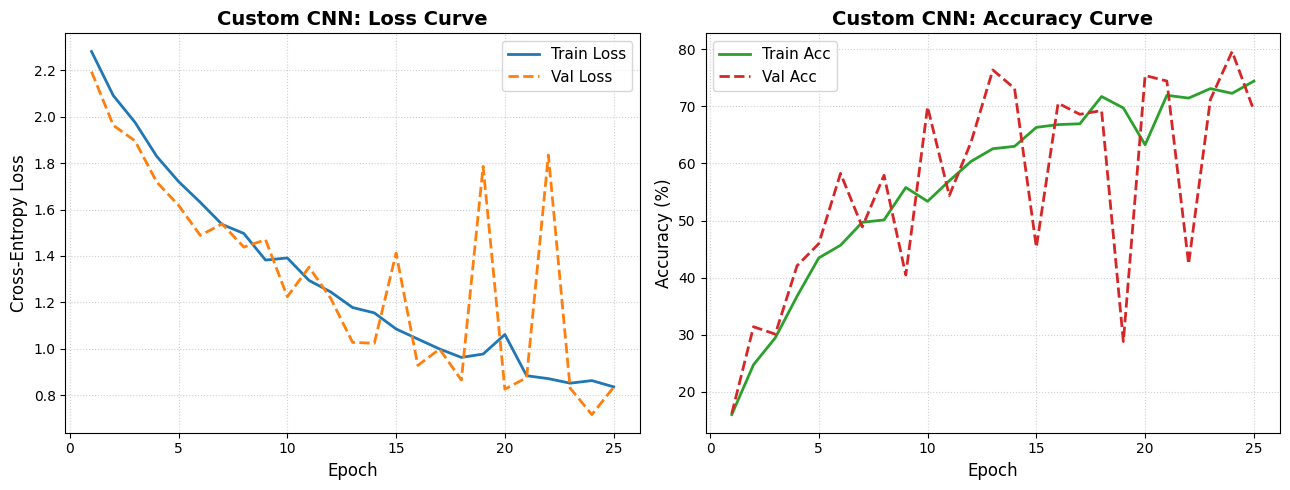

Saved: outputs/learning_curves.png


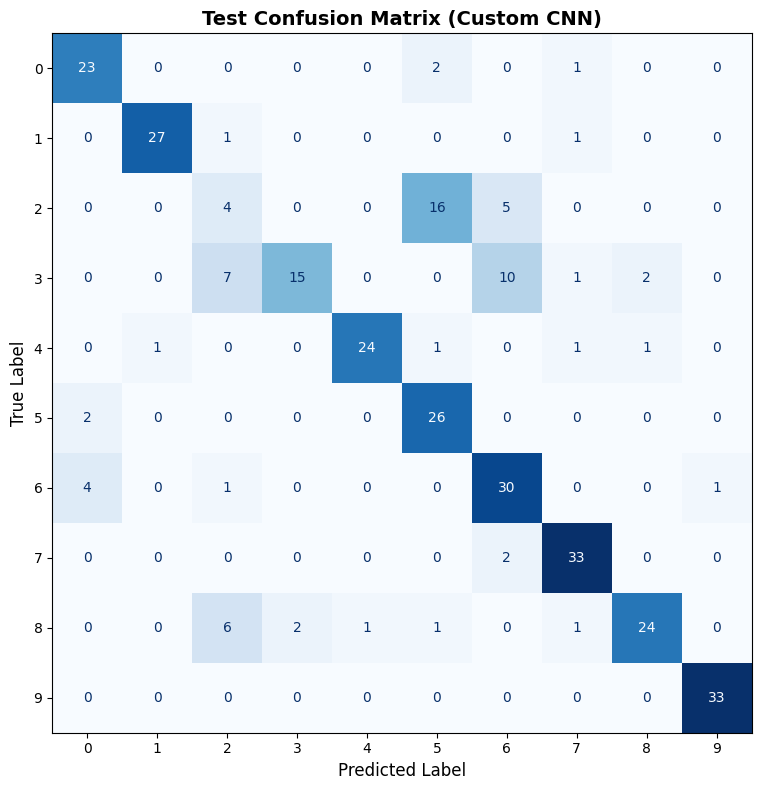

Saved: outputs/confusion_matrix.png


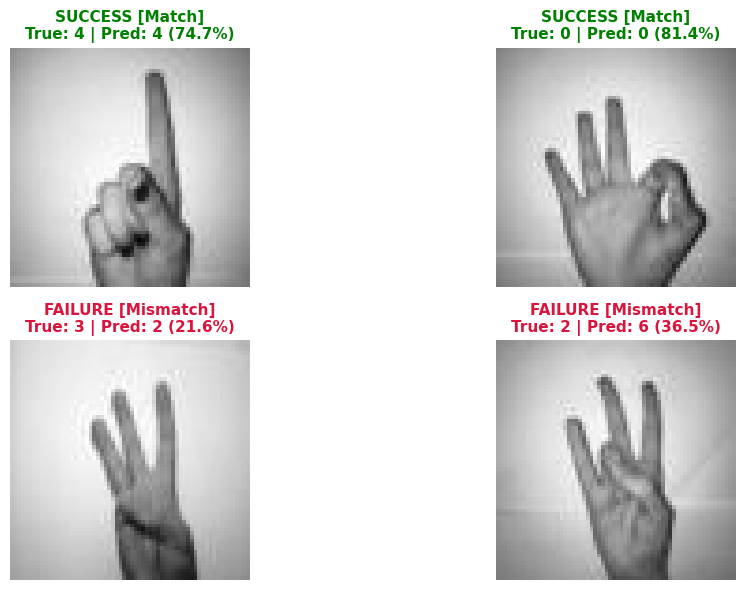

Saved: outputs/success_vs_failure.png


In [4]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# สร้างโฟลเดอร์เก็บไฟล์ผลลัพธ์
os.makedirs("outputs", exist_ok=True)

# -------------------------------------------------------------
# 1. พลอตกราฟ Learning Curves (Train vs. Val Loss และ Accuracy)
# -------------------------------------------------------------
epochs_range = range(1, len(hist_cnn["train_loss"]) + 1)

plt.figure(figsize=(13, 5))

# กราฟ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, hist_cnn["train_loss"], label="Train Loss", color="#1f77b4", linewidth=2)
plt.plot(epochs_range, hist_cnn["val_loss"], label="Val Loss", color="#ff7f0e", linewidth=2, linestyle="--")
plt.title("Custom CNN: Loss Curve", fontsize=14, fontweight="bold")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)

# กราฟ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [acc * 100 for acc in hist_cnn["train_acc"]], label="Train Acc", color="#2ca02c", linewidth=2)
plt.plot(epochs_range, [acc * 100 for acc in hist_cnn["val_acc"]], label="Val Acc", color="#d62728", linewidth=2, linestyle="--")
plt.title("Custom CNN: Accuracy Curve", fontsize=14, fontweight="bold")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("outputs/learning_curves.png", dpi=200)
plt.show()
print("Saved: outputs/learning_curves.png")

# -------------------------------------------------------------
# 2. ทำ Inference บน Test Set และสร้าง Confusion Matrix
# -------------------------------------------------------------
# โหลดน้ำหนักโมเดลที่ดีที่สุด
best_model = SignLanguageCNN(num_classes=10).to(device)
best_model.load_state_dict(torch.load("best_cnn.pth", map_location=device))
best_model.eval()

all_preds = []
all_labels = []
all_probs = []
all_images = []

with torch.no_grad():
    for images, labels in test_loader:
        images_dev = images.to(device)
        outputs = best_model(images_dev)
        probs = torch.softmax(outputs, dim=1)
        max_probs, preds = torch.max(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(max_probs.cpu().numpy())
        all_images.extend(images.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)
all_images = np.array(all_images)

# พลอต Confusion Matrix
class_names = [str(i) for i in range(10)]
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Test Confusion Matrix (Custom CNN)", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=200)
plt.show()
print("Saved: outputs/confusion_matrix.png")

# -------------------------------------------------------------
# 3. สกัดและพรีวิวภาพ Success Case vs. Failure Case
# -------------------------------------------------------------
def unnormalize(img_tensor):
    """แปลงกลับจาก [-1, 1] เป็นภาพ RGB [0, 1]"""
    img = np.transpose(img_tensor, (1, 2, 0))
    img = img * 0.5 + 0.5
    return np.clip(img, 0.0, 1.0)

# ค้นหา Index ของภาพที่ทายถูกและทายผิด
correct_indices = np.where(all_labels == all_preds)[0]
wrong_indices = np.where(all_labels != all_preds)[0]

# สุ่มเลือกตัวอย่างละ 2 ภาพ
np.random.seed(42)
sampled_correct = np.random.choice(correct_indices, size=min(2, len(correct_indices)), replace=False)
sampled_wrong = np.random.choice(wrong_indices, size=min(2, len(wrong_indices)), replace=False)

plt.figure(figsize=(12, 6))

# พลอต Success Cases
for i, idx in enumerate(sampled_correct):
    plt.subplot(2, 2, i + 1)
    plt.imshow(unnormalize(all_images[idx]))
    plt.title(f"SUCCESS [Match]\nTrue: {all_labels[idx]} | Pred: {all_preds[idx]} ({all_probs[idx]*100:.1f}%)",
              color="green", fontweight="bold", fontsize=11)
    plt.axis("off")

# พลอต Failure Cases
for i, idx in enumerate(sampled_wrong):
    plt.subplot(2, 2, i + 3)
    plt.imshow(unnormalize(all_images[idx]))
    plt.title(f"FAILURE [Mismatch]\nTrue: {all_labels[idx]} | Pred: {all_preds[idx]} ({all_probs[idx]*100:.1f}%)",
              color="crimson", fontweight="bold", fontsize=11)
    plt.axis("off")

plt.tight_layout()
plt.savefig("outputs/success_vs_failure.png", dpi=200)
plt.show()
print("Saved: outputs/success_vs_failure.png")